# Exercise No 12: K-Means Clustering using PySpark
### Objective: Perform Customer Segmentation using PySpark MLlib KMeans, find optimal $k$ using Elbow Method & Silhouette Score, and visualize clusters.

## 1. Initialize PySpark Session & Import Libraries

In [ ]:
import os
import sys
if "JAVA_HOME" not in os.environ:
    os.environ["JAVA_HOME"] = os.path.expanduser("~/.jdk17")
    os.environ["PATH"] = f"{os.path.expanduser('~/.jdk17')}/bin:" + os.environ.get("PATH", "")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pyspark.sql import SparkSession
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import ClusteringEvaluator

spark = SparkSession.builder \
    .appName("Ex12_KMeans_Clustering") \
    .master("local[*]") \
    .getOrCreate()

spark.sparkContext.setLogLevel("ERROR")
print(f"Spark Version: {spark.version}")

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
/home/ghua/bda/.venv/lib/python3.12/site-packages/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
26/08/18 22:59:51 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/08/18 22:59:52 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.


Spark Version: 4.2.0


## 2. Load & Explore the K-Means Dataset

In [3]:
df = spark.read.csv("kmeans_dataset.csv", header=True, inferSchema=True)
print(f"Dataset Shape: ({df.count()}, {len(df.columns)})")
df.show(10)

Dataset Shape: (300, 5)
+----------+---+-------------+--------------+---------------+
|CustomerID|Age|Annual_Income|Spending_Score|Total_Purchases|
+----------+---+-------------+--------------+---------------+
|      1001| 51|         93.8|          19.1|             21|
|      1002| 33|         96.3|          81.8|             60|
|      1003| 36|         42.1|          56.1|             21|
|      1004| 40|         28.3|          15.5|              9|
|      1005| 56|         80.8|          18.1|             20|
|      1006| 30|         84.6|          18.1|             25|
|      1007| 37|         84.7|          31.9|             28|
|      1008| 22|         24.3|          73.5|             40|
|      1009| 67|         23.6|          29.5|             18|
|      1010| 39|         51.1|          51.7|             24|
+----------+---+-------------+--------------+---------------+
only showing top 10 rows


## 3. Feature Assembly & Scaling Pipeline

In [4]:
feature_cols = ["Age", "Annual_Income", "Spending_Score", "Total_Purchases"]

# Vector Assembler
assembler = VectorAssembler(inputCols=feature_cols, outputCol="rawFeatures")
assembled_df = assembler.transform(df)

# Standard Scaler
scaler = StandardScaler(inputCol="rawFeatures", outputCol="features", withStd=True, withMean=True)
scaler_model = scaler.fit(assembled_df)
scaled_df = scaler_model.transform(assembled_df)

scaled_df.select("CustomerID", "features").show(5, truncate=False)

+----------+---------------------------------------------------------------------------------+
|CustomerID|features                                                                         |
+----------+---------------------------------------------------------------------------------+
|1001      |[1.2153511102987726,1.3565987615278194,-1.1572078619769144,-0.6484105231417254]  |
|1002      |[-0.47829946921435884,1.4467318259525659,1.2135463594232683,2.216545338171791]   |
|1003      |[-0.1960243726288369,-0.5073530107759361,0.24180180615397492,-0.6484105231417254]|
|1004      |[0.18034242281852567,-1.0048875264005364,-1.2933277215788388,-1.5299354035458843]|
|1005      |[1.685809604607976,0.8879068265191381,-1.1950189340885602,-0.7218709298420719]   |
+----------+---------------------------------------------------------------------------------+
only showing top 5 rows


## 4. Determine Optimal $k$ (Elbow Curve & Silhouette Score)

netlib-blas: JNI_OnLoad: dlopen(libblas.so.3) failed: libblas.so.3: cannot open shared object file: No such file or directory


k = 2 | Silhouette Score = 0.5833 | Training Cost (WSSSE) = 643.36
k = 3 | Silhouette Score = 0.5707 | Training Cost (WSSSE) = 479.91
k = 4 | Silhouette Score = 0.5015 | Training Cost (WSSSE) = 377.25
k = 5 | Silhouette Score = 0.6376 | Training Cost (WSSSE) = 251.30
k = 6 | Silhouette Score = 0.6345 | Training Cost (WSSSE) = 214.69
k = 7 | Silhouette Score = 0.5782 | Training Cost (WSSSE) = 199.16
k = 8 | Silhouette Score = 0.5724 | Training Cost (WSSSE) = 170.21


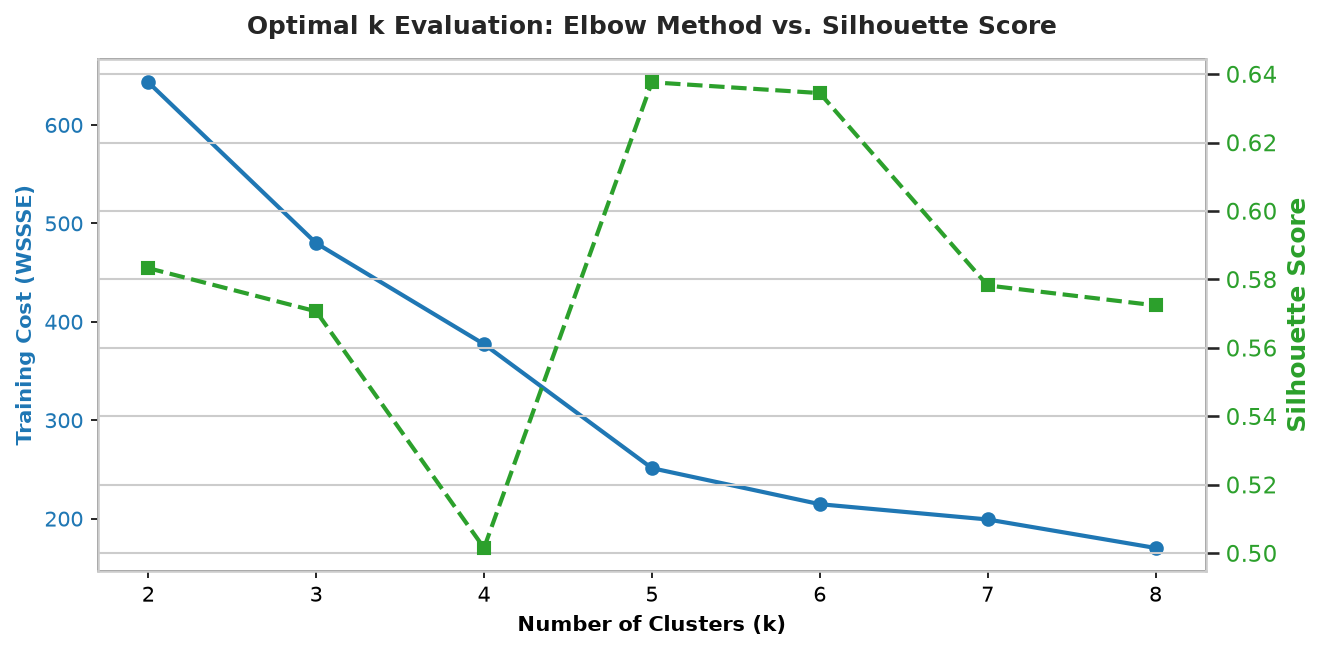

In [5]:
k_values = list(range(2, 9))
silhouette_scores = []
cost_values = []

evaluator = ClusteringEvaluator(featuresCol="features", predictionCol="prediction", metricName="silhouette")

for k in k_values:
    kmeans = KMeans(featuresCol="features", k=k, seed=42)
    model = kmeans.fit(scaled_df)
    predictions = model.transform(scaled_df)
    
    score = evaluator.evaluate(predictions)
    cost = model.summary.trainingCost
    
    silhouette_scores.append(score)
    cost_values.append(cost)
    print(f"k = {k} | Silhouette Score = {score:.4f} | Training Cost (WSSSE) = {cost:.2f}")

# Plot Elbow and Silhouette Graphs
fig, ax1 = plt.subplots(figsize=(9, 4.5), dpi=150)
sns.set_theme(style="whitegrid")

color = 'tab:blue'
ax1.set_xlabel('Number of Clusters (k)', fontweight='bold')
ax1.set_ylabel('Training Cost (WSSSE)', color=color, fontweight='bold')
ax1.plot(k_values, cost_values, marker='o', color=color, linewidth=2)
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color = 'tab:green'
ax2.set_ylabel('Silhouette Score', color=color, fontweight='bold')
ax2.plot(k_values, silhouette_scores, marker='s', color=color, linewidth=2, linestyle='--')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Optimal k Evaluation: Elbow Method vs. Silhouette Score', fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

## 5. Fit Final K-Means Model ($k=5$) & Assign Clusters

In [6]:
optimal_k = 5
kmeans_final = KMeans(featuresCol="features", k=optimal_k, seed=42)
model_final = kmeans_final.fit(scaled_df)

# Predict clusters
clustered_df = model_final.transform(scaled_df)
clustered_df.select("CustomerID", "Age", "Annual_Income", "Spending_Score", "prediction").show(10)

# Cluster Counts
clustered_df.groupBy("prediction").count().orderBy("prediction").show()

+----------+---+-------------+--------------+----------+
|CustomerID|Age|Annual_Income|Spending_Score|prediction|
+----------+---+-------------+--------------+----------+
|      1001| 51|         93.8|          19.1|         4|
|      1002| 33|         96.3|          81.8|         1|
|      1003| 36|         42.1|          56.1|         0|
|      1004| 40|         28.3|          15.5|         2|
|      1005| 56|         80.8|          18.1|         4|
|      1006| 30|         84.6|          18.1|         4|
|      1007| 37|         84.7|          31.9|         4|
|      1008| 22|         24.3|          73.5|         3|
|      1009| 67|         23.6|          29.5|         2|
|      1010| 39|         51.1|          51.7|         0|
+----------+---+-------------+--------------+----------+
only showing top 10 rows
+----------+-----+
|prediction|count|
+----------+-----+
|         0|   78|
|         1|   55|
|         2|   59|
|         3|   50|
|         4|   58|
+----------+-----+



## 6. Cluster Profiling & Visualization

/home/ghua/bda/.venv/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/home/ghua/bda/.venv/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


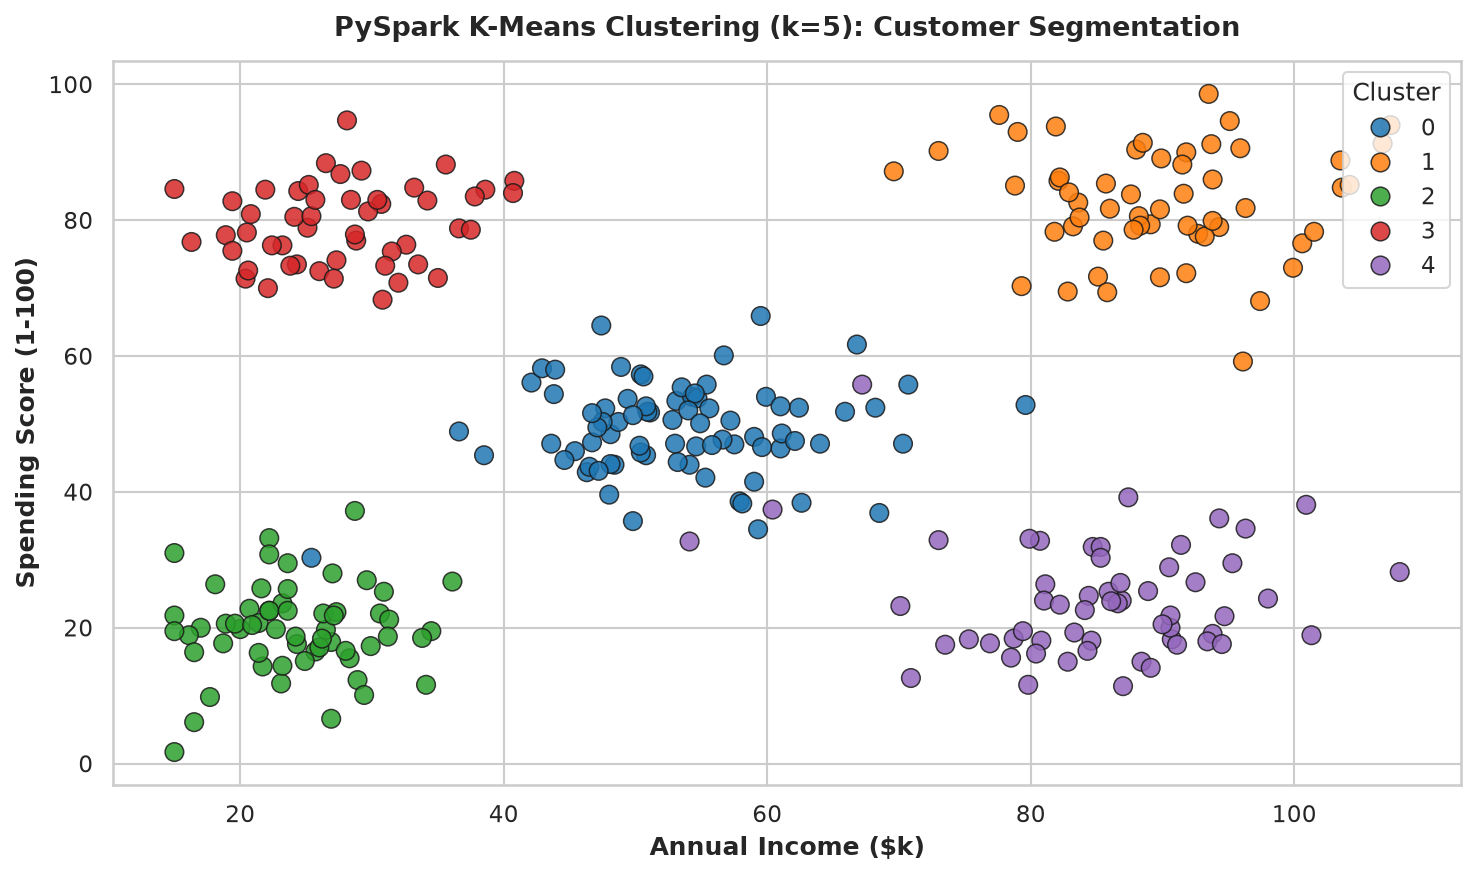

,Age,Annual_Income,Spending_Score,Total_Purchases
Cluster,,,,
0,37.60,53.43,49.18,27.37
1,33.71,89.79,82.59,49.56
2,46.19,24.12,19.80,15.17
3,25.30,27.78,79.34,40.42
4,45.66,85.06,24.11,20.19


In [7]:
# Convert to Pandas for visualization
pdf = clustered_df.select("CustomerID", "Age", "Annual_Income", "Spending_Score", "Total_Purchases", "prediction").toPandas()
pdf.rename(columns={"prediction": "Cluster"}, inplace=True)

# 2D Scatter Plot: Annual Income vs Spending Score
plt.figure(figsize=(10, 6), dpi=150)
sns.set_theme(style="whitegrid")

scatter = sns.scatterplot(
    data=pdf,
    x="Annual_Income",
    y="Spending_Score",
    hue="Cluster",
    palette="tab10",
    s=80,
    alpha=0.85,
    edgecolor="k"
)

plt.title(f"PySpark K-Means Clustering (k={optimal_k}): Customer Segmentation", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Annual Income ($k)", fontweight='bold')
plt.ylabel("Spending Score (1-100)", fontweight='bold')
plt.legend(title="Cluster", loc="upper right", frameon=True)
plt.tight_layout()
plt.show()

# Summary statistics per cluster
cluster_profile = pdf.groupby("Cluster")[["Age", "Annual_Income", "Spending_Score", "Total_Purchases"]].mean().round(2)
display(cluster_profile)